# 07 · Optimise a tree surrogate in Pyomo

Train a HyperplaneTree, embed it in a Pyomo model with `embed_in_pyomo_model`, and solve the resulting MILP with HiGHS. The embedding is exact: the MILP's objective *is* the tree's piecewise-linear prediction, so the solver returns the surrogate's global optimum, with or without extra constraints.

Requires `pip install jax-ldt[pyomo] highspy`.


In [1]:
import os
os.environ["JAX_ENABLE_X64"] = "1"

import jax
jax.config.update("jax_enable_x64", True)

import matplotlib.pyplot as plt
import numpy as np
import pyomo
import pyomo.environ as pyo

from jax_ldt import HyperplaneTreeRegressor
from jax_ldt.export import embed_in_pyomo_model

solver = pyo.SolverFactory("appsi_highs")
print("pyomo", pyomo.__version__, "| HiGHS available:", solver.available())


pyomo 6.10.1 | HiGHS available: True


## Train a surrogate

In [2]:
def f(X):
    return (X[:, 0] - 0.5) ** 2 + 2 * (X[:, 1] + 0.3) ** 2 + 0.5 * np.sin(3 * X[:, 0])

rng = np.random.default_rng(0)
X = rng.uniform(-2, 2, size=(600, 2))
y = f(X)
model = HyperplaneTreeRegressor(
    max_depth=5, max_bins=8, min_samples_leaf=15, max_weight=1, num_terms=2,
).fit(X, y)
print(f"train MAE: {np.mean(np.abs(model.predict(X) - y)):.3f}, leaves: {model.num_leaves}")


train MAE: 0.086, leaves: 23


## Embed it in a Pyomo model

`embed_in_pyomo_model(model, m, x)` adds a sub-block `m.tree` holding the lifted hyperplane features, one binary per leaf, big-M routing constraints for every split, and big-M-linearised leaf regressions. It returns one Pyomo variable per output target. The big-M constants are computed per split and per leaf from the bounds on `m.x`, so always give the inputs finite bounds.


In [3]:
m = pyo.ConcreteModel()
m.x = pyo.Var(range(2), bounds=(-2, 2))
y_tree = embed_in_pyomo_model(model, m, m.x)
m.obj = pyo.Objective(expr=y_tree[0], sense=pyo.minimize)

n_bin = sum(v.is_binary() for v in m.component_data_objects(pyo.Var))
n_con = sum(1 for _ in m.component_data_objects(pyo.Constraint))
print(f"lifted features: {len(m.tree.xt)}, binaries: {n_bin}, constraints: {n_con}")


lifted features: 4, binaries: 23, constraints: 142


## Unconstrained minimum

In [4]:
res = solver.solve(m)
print(res.solver.termination_condition)
x_unc = np.array([pyo.value(m.x[i]) for i in range(2)])
print("argmin x :", x_unc.round(4))
print("MILP y   :", round(pyo.value(m.obj), 4))

# Sanity check against a dense grid of predictions.
g = np.linspace(-2, 2, 201)
G = np.stack(np.meshgrid(g, g), axis=-1).reshape(-1, 2)
yG = np.asarray(model.predict(G))
print("grid min :", round(float(yG.min()), 4))


optimal
argmin x : [-0.0951 -0.0607]
MILP y   : -0.3199
grid min : -0.2889


The MILP finds a lower value than any grid point. Where is it? Trees are *discontinuous* at their splits, and the optimum of a piecewise-linear function often sits right on a split. Let's look at which split hyperplanes pass through `x*`, and what `predict` gives just either side.


In [5]:
t = model.tree_
xt = x_unc @ np.asarray(t.transform_matrix)        # lifted features at x*
internal = np.where(~np.asarray(t.is_leaf))[0]
gap = xt[np.asarray(t.feature)[internal]] - np.asarray(t.threshold)[internal]
print("splits through x* (node, x'_f - t):",
      [(int(n), f"{d:.1e}") for n, d in zip(internal, gap) if abs(d) < 1e-9])

active = [k for k in m.tree.z if pyo.value(m.tree.z[k]) > 0.5]
print("MILP active leaf index:", active)
for dx in (-1e-7, 0.0, 1e-7):
    p = x_unc + np.array([0.0, dx])
    print(f"predict(x* + [0, {dx:+.0e}]) = {float(model.predict(p[None])[0]):+.4f}")
print("true f(x*) =", round(float(f(x_unc[None])[0]), 4))


splits through x* (node, x'_f - t): [(0, '1.9e-15'), (1, '-5.6e-15')]
MILP active leaf index: [18]


predict(x* + [0, -1e-07]) = -0.3199
predict(x* + [0, +0e+00]) = +0.3236
predict(x* + [0, +1e-07]) = +0.3236
true f(x*) = 0.3279


`x*` lies on the root split (x1 = t, up to ~1e-15), where the surrogate jumps from about -0.32 (left leaf) to +0.32 (right leaf). The MILP's value is attained by the left leaf, which owns the boundary (`predict` sends `x'_f <= t` left), and `predict` just below the split reproduces it. At `x*` itself the solver's answer is ~1e-15 on the wrong side of the threshold, within its feasibility tolerance, so `predict(x*)` lands in the right leaf.

Two take-aways: the MILP optimises the tree itself, not an approximation of it; and surrogate optima often sit on a discontinuity, where the tree's value is an artefact of the fit (the true `f` here is ~0.33). Always check the optimum against the true model, and consider a deeper tree or more data near the optimum.

## Adding constraints

Because the surrogate is just part of a Pyomo model, any other constraints compose naturally. Here we require `x0 + x1 >= 1`, which excludes the unconstrained optimum.


In [6]:
m.cut = pyo.Constraint(expr=m.x[0] + m.x[1] >= 1)
solver.solve(m)
x_con = np.array([pyo.value(m.x[i]) for i in range(2)])
print("argmin x :", x_con.round(3), " (x0 + x1 =", round(x_con.sum(), 3), ")")
print("MILP y   :", round(pyo.value(m.obj), 4))
print("grid min :", round(float(yG[G.sum(axis=1) >= 1].min()), 4))


argmin x : [ 1.273 -0.061]  (x0 + x1 = 1.213 )
MILP y   : -0.0045
grid min : 0.0134


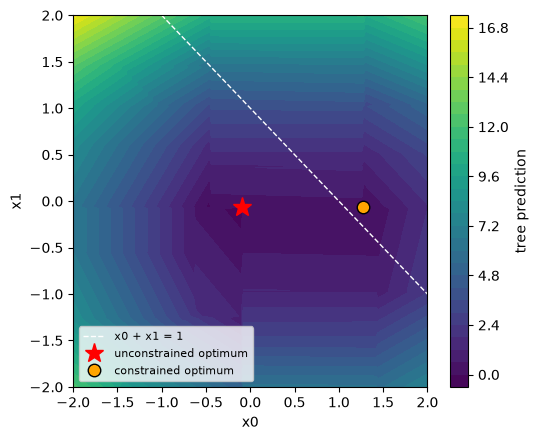

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cs = ax.contourf(g, g, yG.reshape(len(g), len(g)), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="tree prediction")
ax.plot(g, 1 - g, "w--", lw=1, label="x0 + x1 = 1")
ax.plot(*x_unc, "r*", ms=14, label="unconstrained optimum")
ax.plot(*x_con, "o", mfc="orange", mec="k", ms=9, label="constrained optimum")
ax.set(xlim=(-2, 2), ylim=(-2, 2), xlabel="x0", ylabel="x1")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()


The faceted contours are the hyperplane tree's oblique leaf regions; the optima sit on region boundaries or corners, as expected for a piecewise-linear objective.

## Checking the embedding pointwise

Fixing `x` turns the MILP into an evaluation of the tree. The embedded output should match `model.predict` everywhere.


In [8]:
m.cut.deactivate()
P = rng.uniform(-1.9, 1.9, size=(10, 2))
errs = []
for p in P:
    for i in range(2):
        m.x[i].fix(float(p[i]))
    solver.solve(m)
    errs.append(abs(pyo.value(m.obj) - float(model.predict(p[None])[0])))
m.x.unfix()
print(f"max |MILP - predict| over {len(P)} points: {max(errs):.1e}")


max |MILP - predict| over 10 points: 1.8e-15


## Notes

* The sub-block name defaults to `tree`; pass `name=...` to embed several surrogates in one model.
* `x_vars` can be an indexed `Var` or any list of Pyomo variables or linear expressions, so the tree's inputs can be derived quantities of a larger model.
* The formulation is a pure MILP, so any Pyomo MILP solver (HiGHS, Gurobi, CPLEX, CBC, ...) works; it also composes with nonlinear constraints in an MINLP.
* At a split threshold, `predict` routes left; the MILP may route either way. Pass `boundary_eps > 0` if the tie-break matters.
